In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score


## Exploratory Data Analysis 

In [3]:
df = pd.read_csv("wine.csv")
df.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [2]:
# Display number of rows and columns
df.shape

(178, 14)

In [4]:
#Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [5]:
#statistical summary
df.describe()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [7]:
#chekcing the null values present or not
df.isnull().sum()

Type               0
Alcohol            0
Malic              0
Ash                0
Alcalinity         0
Magnesium          0
Phenols            0
Flavanoids         0
Nonflavanoids      0
Proanthocyanins    0
Color              0
Hue                0
Dilution           0
Proline            0
dtype: int64

In [8]:
#checking the duplicate values
df.duplicated().sum()

np.int64(0)

In [10]:
#checking the distribution types
df["Type"].value_counts()

Type
2    71
1    59
3    48
Name: count, dtype: int64

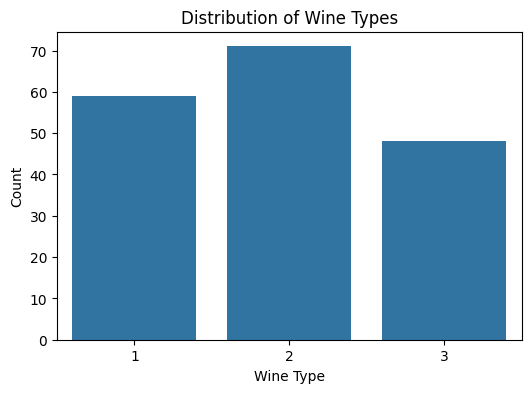

In [12]:
#visualizing it
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Type"
)

plt.title("Distribution of Wine Types")
plt.xlabel("Wine Type")
plt.ylabel("Count")

plt.show()


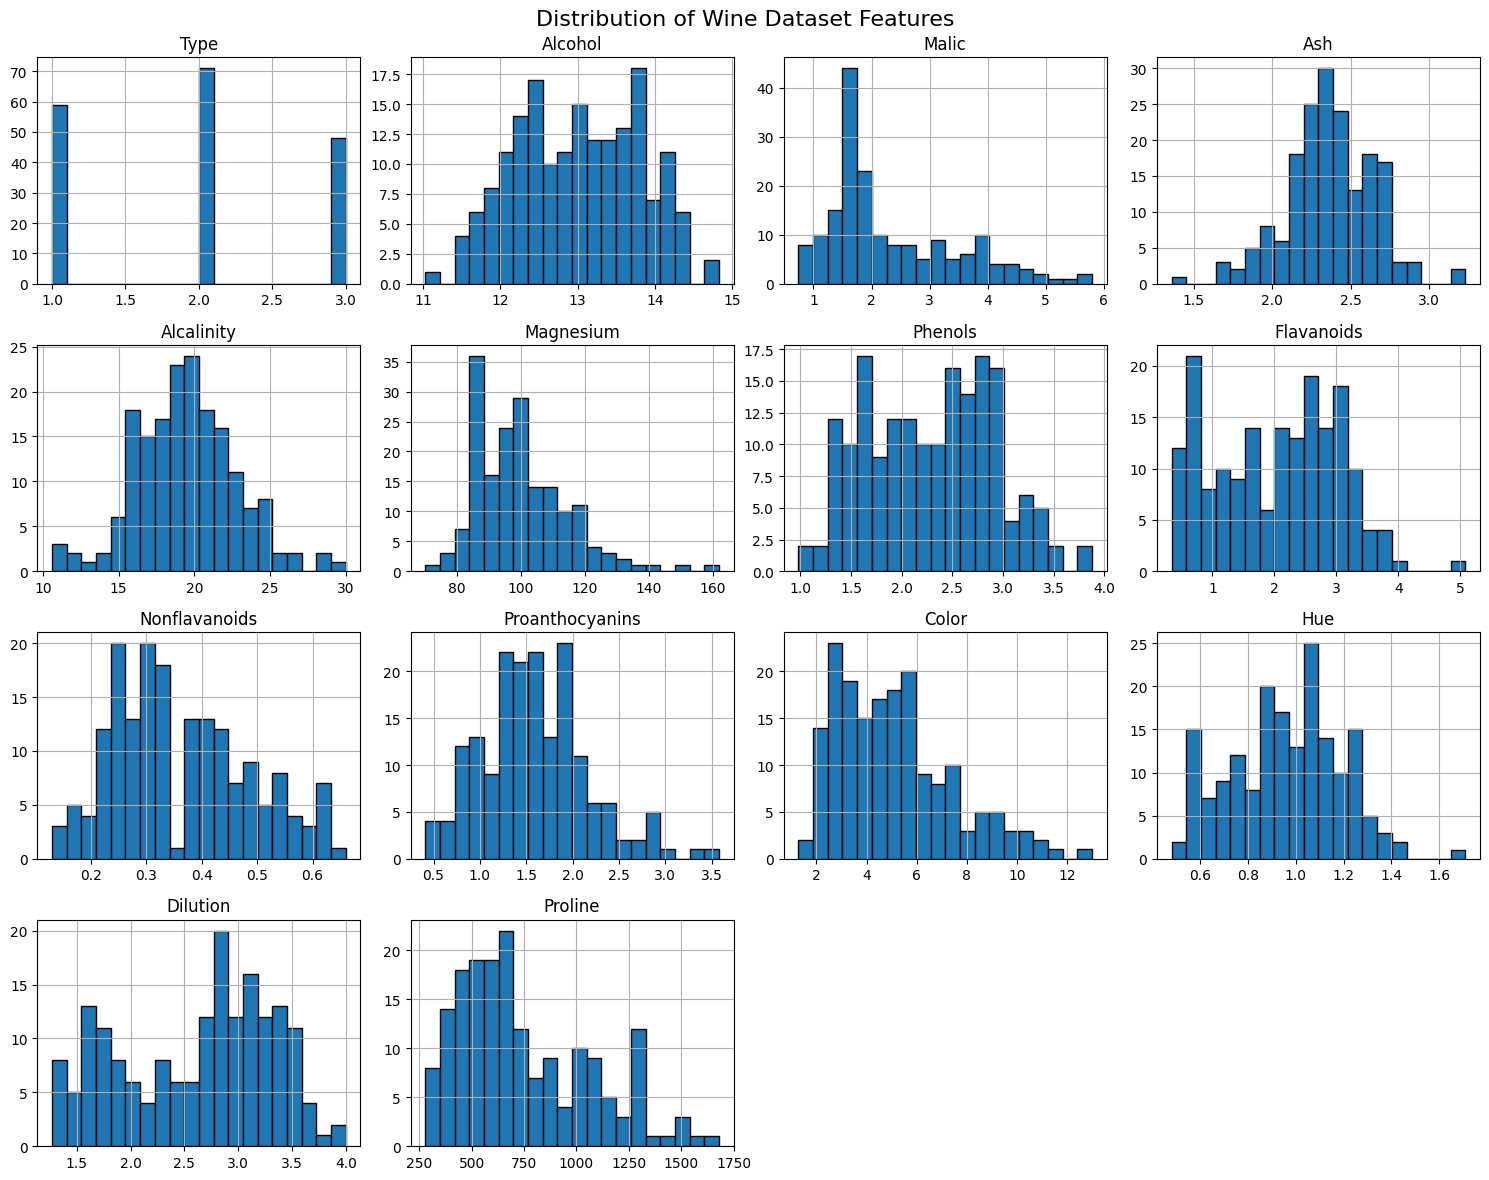

In [13]:
#histogram
df.hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Wine Dataset Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

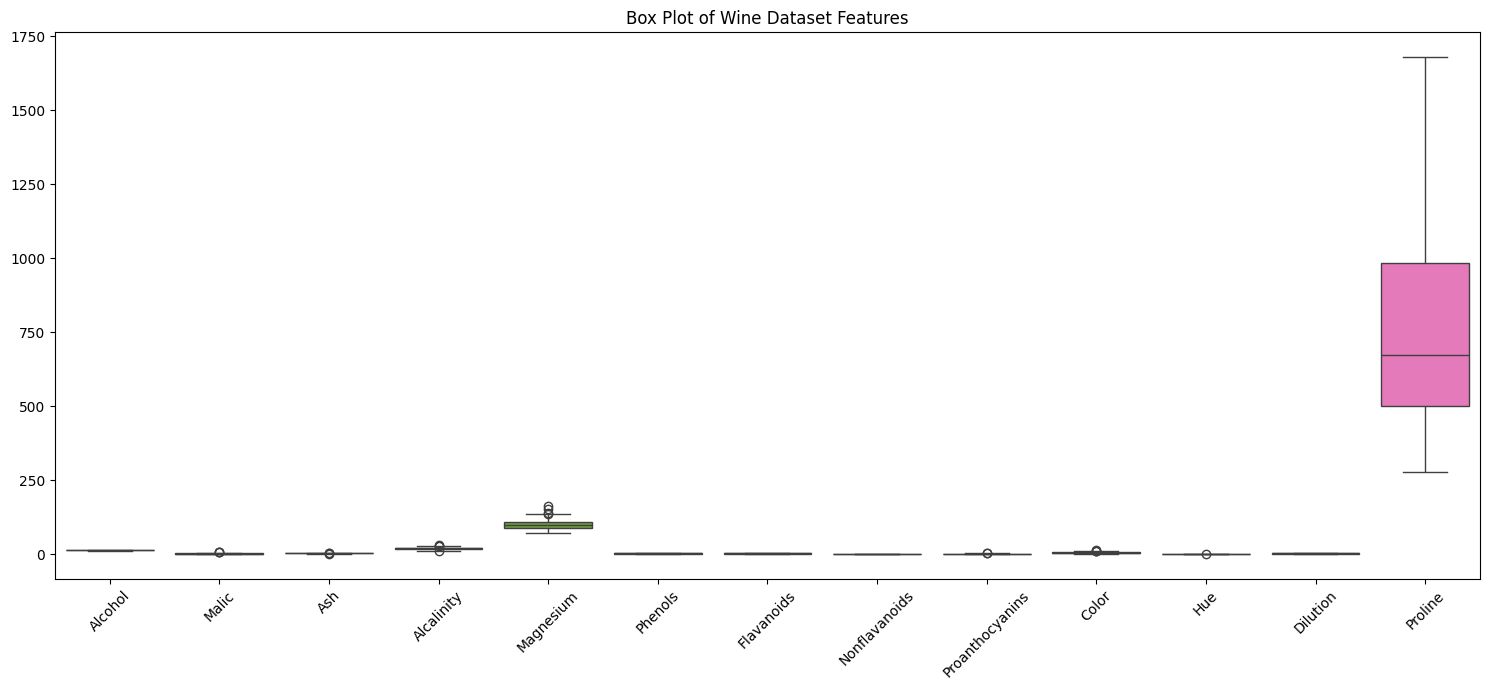

In [14]:
#boxplot
plt.figure(figsize=(15, 7))

sns.boxplot(data=df.drop("Type", axis=1))

plt.title("Box Plot of Wine Dataset Features")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

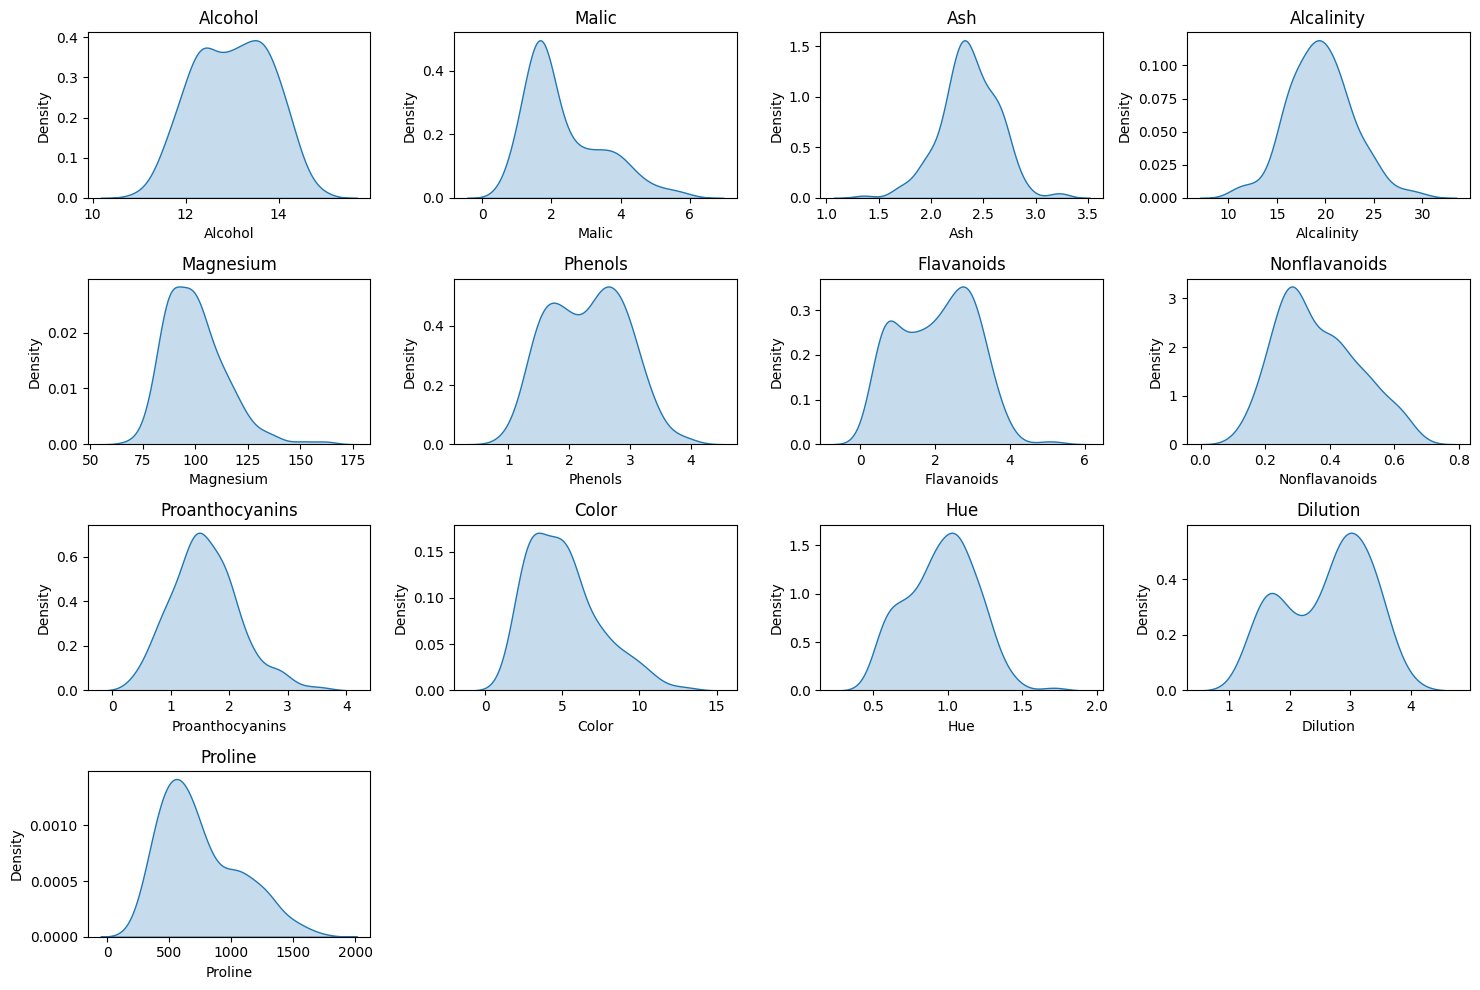

In [15]:
#density plots
plt.figure(figsize=(15, 10))

for i, column in enumerate(df.drop("Type", axis=1).columns, 1):

    plt.subplot(4, 4, i)

    sns.kdeplot(
        data=df,
        x=column,
        fill=True
    )

    plt.title(column)

plt.tight_layout()
plt.show()

In [16]:
#correlation between features
features = df.drop("Type", axis=1)

correlation = features.corr()

display(correlation)

,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
Alcohol,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720
Malic,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011
Ash,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626
Alcalinity,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597
Magnesium,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351
Phenols,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115
Flavanoids,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193
Nonflavanoids,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385
Proanthocyanins,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417
Color,0.546364,0.248985,0.258887,0.018732,0.199950,-0.055136,-0.172379,0.139057,-0.025250,1.000000,-0.521813,-0.428815,0.316100


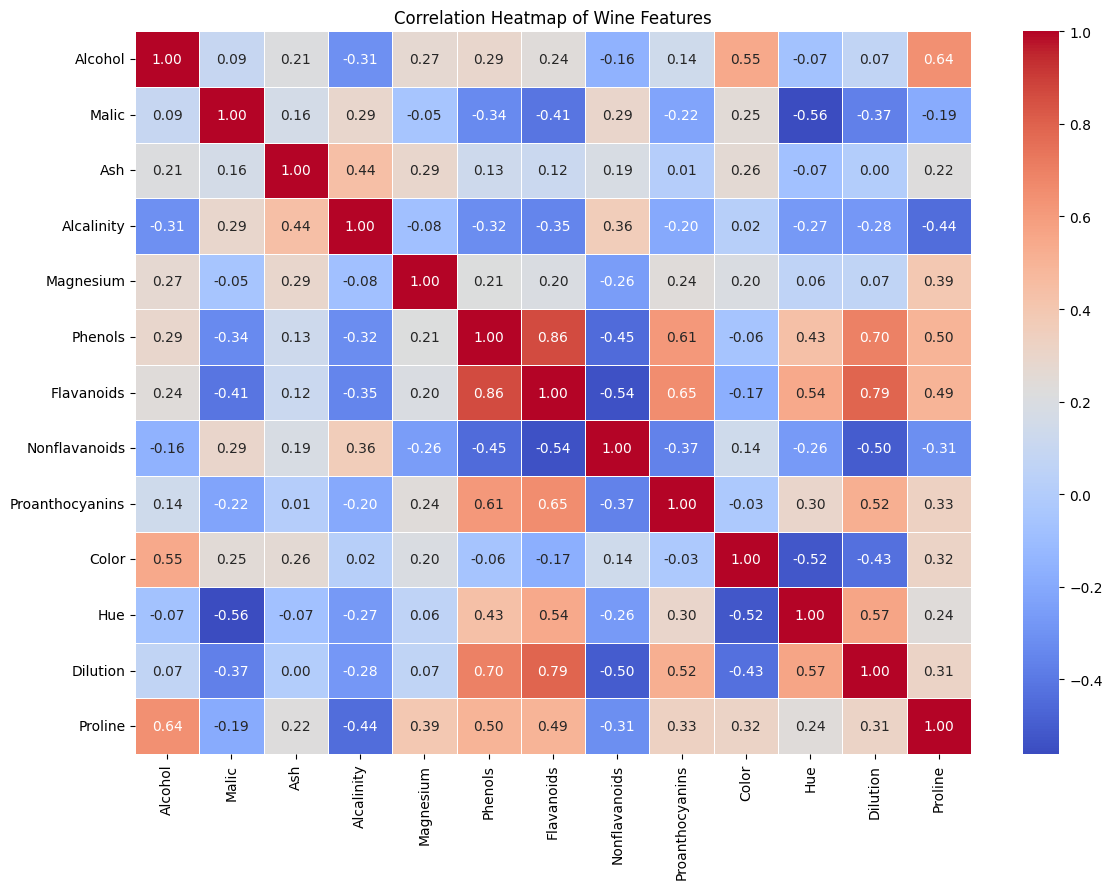

In [17]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Features")

plt.tight_layout()
plt.show()

In [18]:
corr_pairs = (
    correlation
    .where(np.triu(
        np.ones(correlation.shape),
        k=1
    ).astype(bool))
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("Strongest correlations:")
print(corr_pairs.head(10))

Strongest correlations:
Phenols     Flavanoids         0.864564
Flavanoids  Dilution           0.787194
Phenols     Dilution           0.699949
Flavanoids  Proanthocyanins    0.652692
Alcohol     Proline            0.643720
Phenols     Proanthocyanins    0.612413
Hue         Dilution           0.565468
Malic       Hue               -0.561296
Alcohol     Color              0.546364
Flavanoids  Hue                0.543479
dtype: float64


#  Dimensionality Reduction with PCA

In [21]:
#type column is the target so we do not use for the pca
X = df.drop("Type", axis=1)

X.shape

(178, 13)

In [22]:
#standardize the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [25]:
#mean of the standard scaler
print(X_scaled.mean(axis=0))

print("Standard deviation of standardized features:")
print(X_scaled.std(axis=0))

[-8.38280756e-16 -1.19754394e-16 -8.37033314e-16 -3.99181312e-17
 -3.99181312e-17  0.00000000e+00 -3.99181312e-16  3.59263181e-16
 -1.19754394e-16  2.49488320e-17  1.99590656e-16  3.19345050e-16
 -1.59672525e-16]
Standard deviation of standardized features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [26]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled_df.head()

,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [29]:
#applying the pca
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("PCA transformed shape:", X_pca.shape)

explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio:")
print(explained_variance)
cumulative_variance = np.cumsum(explained_variance)
#Cumulative Explained Variance
print("Cumulative explained variance:")
print(cumulative_variance)
#Creating a table
variance_table = pd.DataFrame({
    "Component": range(1, 14),
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

variance_table

PCA transformed shape: (178, 13)
Explained variance ratio:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]
Cumulative explained variance:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


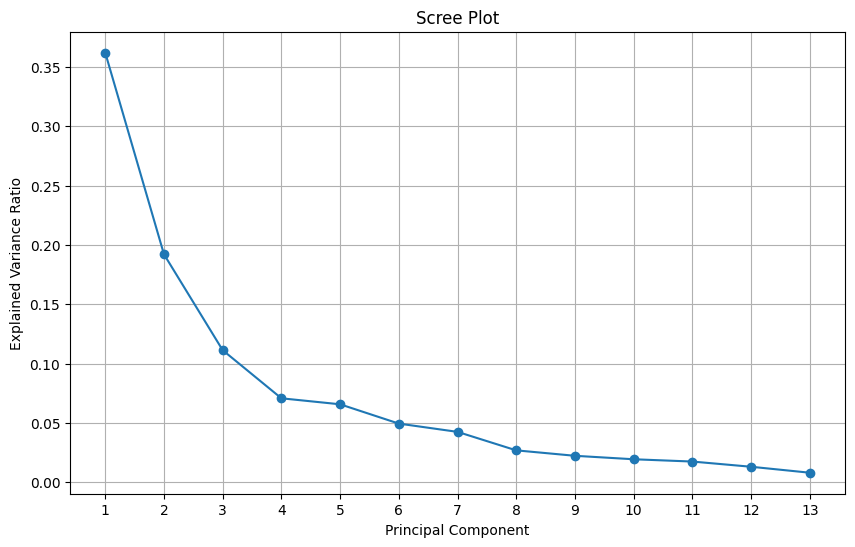

In [31]:
#The scree plot shows the amount of variance explained by each principal component
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 14),
    explained_variance,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")

plt.xticks(range(1, 14))
plt.grid()

plt.show()

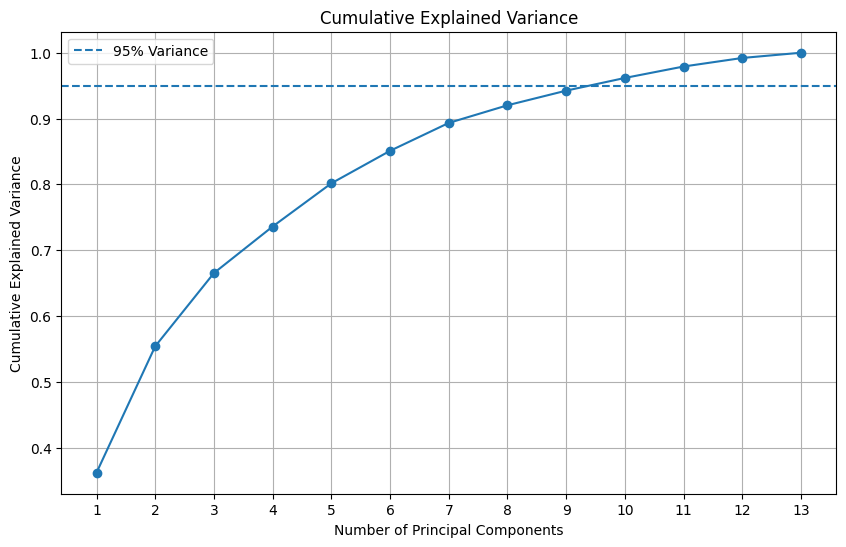

In [33]:
#A cumulative variance plot is useful for selecting the number of components.
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 14),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.95,
    linestyle='--',
    label='95% Variance'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.xticks(range(1, 14))
plt.legend()
plt.grid()

plt.show()

In [34]:
#Determining the Optimal Number of Components
n_components = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Number of components required for 95% variance:",
    n_components
)

Number of components required for 95% variance: 10


In [36]:
#perform the final PCA transformation using 10 components.
pca_final = PCA(n_components=10)

X_pca_final = pca_final.fit_transform(X_scaled)
print("Original feature shape:", X.shape)

print("PCA transformed shape:", X_pca_final.shape)

Original feature shape: (178, 13)
PCA transformed shape: (178, 10)


In [37]:
#Create the PCA DataFrame
pca_columns = [
    "PC1", "PC2", "PC3", "PC4", "PC5",
    "PC6", "PC7", "PC8", "PC9", "PC10"
]

pca_df = pd.DataFrame(
    X_pca_final,
    columns=pca_columns
)

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366


In [38]:
#Add Type Back for Analysis
pca_df["Type"] = df["Type"].values

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Type
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956,1
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701,1
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361,1
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413,1
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366,1


In [41]:
#checking the total variance
total_variance = pca_final.explained_variance_ratio_.sum()

print("Total variance retained:",
      total_variance)

print(
    "Variance retained:",
    round(total_variance * 100, 2),
    "%"
)

Total variance retained: 0.9616971684450643
Variance retained: 96.17 %


In [43]:
#Determine the Number of Clusters Using the Elbow Method
inertia = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

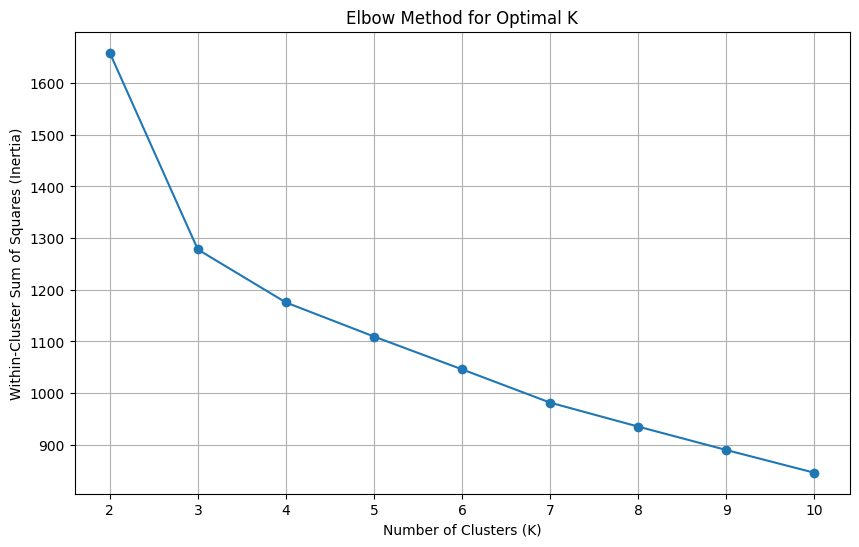

In [45]:
#Plot the Elbow Curve
plt.figure(figsize=(10, 6))

plt.plot(K, inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.title("Elbow Method for Optimal K")

plt.xticks(K)
plt.grid()
plt.show()

# Clustering with Original Data:

In [46]:
#Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [48]:
#Add Cluster Labels to the Dataset
df_clustered = df.copy()

df_clustered["Cluster"] = clusters

df_clustered.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline,Cluster
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,2
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,2
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,2
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,2
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,2


In [49]:
#Check Cluster Distribution
print(df_clustered["Cluster"].value_counts().sort_index())

Cluster
0    65
1    51
2    62
Name: count, dtype: int64


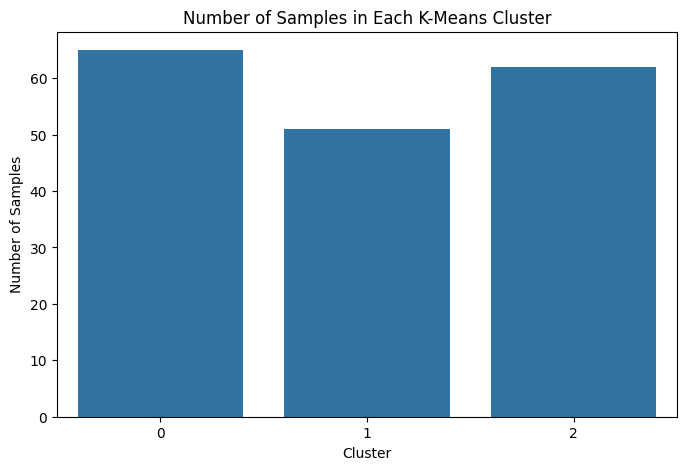

In [50]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clustered,
    x="Cluster"
)

plt.title("Number of Samples in Each K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")

plt.show()

In [52]:
#Visualize Clusters Using PCA
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_scaled)

print("PCA Shape:", X_pca_2d.shape)

PCA Shape: (178, 2)


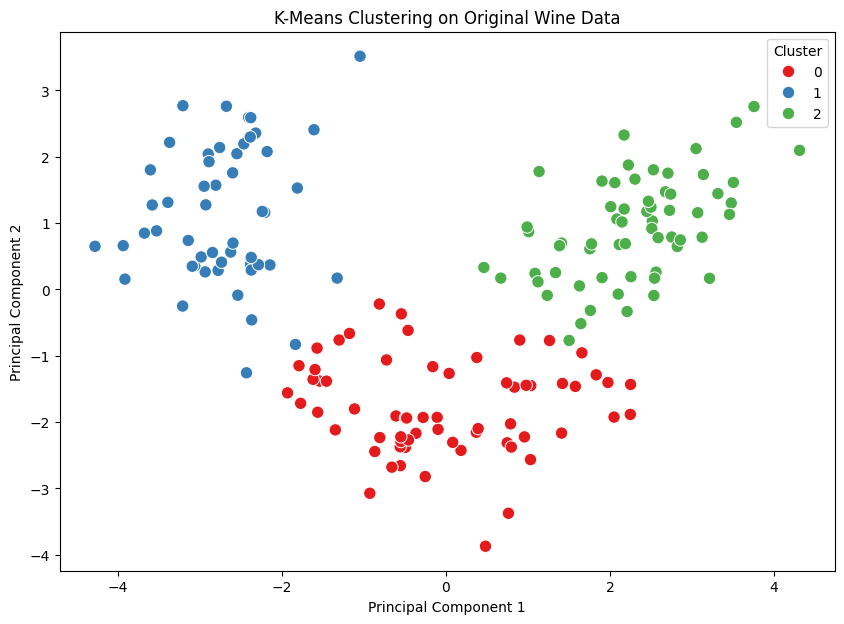

In [53]:
#plot the k-means cluster
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=clusters,
    palette="Set1",
    s=80
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on Original Wine Data")

plt.legend(title="Cluster")

plt.show()

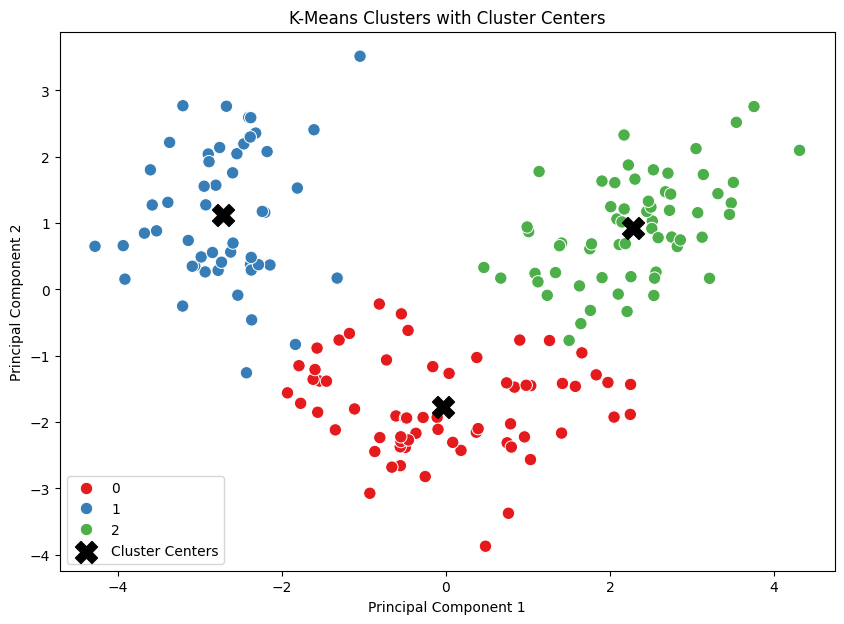

In [54]:
#visualize the cluster centers
centers_pca = pca_2d.transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=clusters,
    palette="Set1",
    s=80
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Cluster Centers"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters with Cluster Centers")

plt.legend()

plt.show()

In [56]:
#Evaluate Using Silhouette Score
silhouette = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", round(silhouette, 4))
#Evaluate Using Davies–Bouldin Index
db_index = davies_bouldin_score(
    X_scaled,
    clusters
)

print("Davies-Bouldin Index:", round(db_index, 4))

Silhouette Score: 0.2849
Davies-Bouldin Index: 1.3892


In [57]:
#Complete Evaluation Code
silhouette = silhouette_score(X_scaled, clusters)

db_index = davies_bouldin_score(X_scaled, clusters)

print("Clustering Evaluation")
print("---------------------")
print("Number of Clusters:", 3)
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(db_index, 4))

Clustering Evaluation
---------------------
Number of Clusters: 3
Silhouette Score: 0.2849
Davies-Bouldin Index: 1.3892


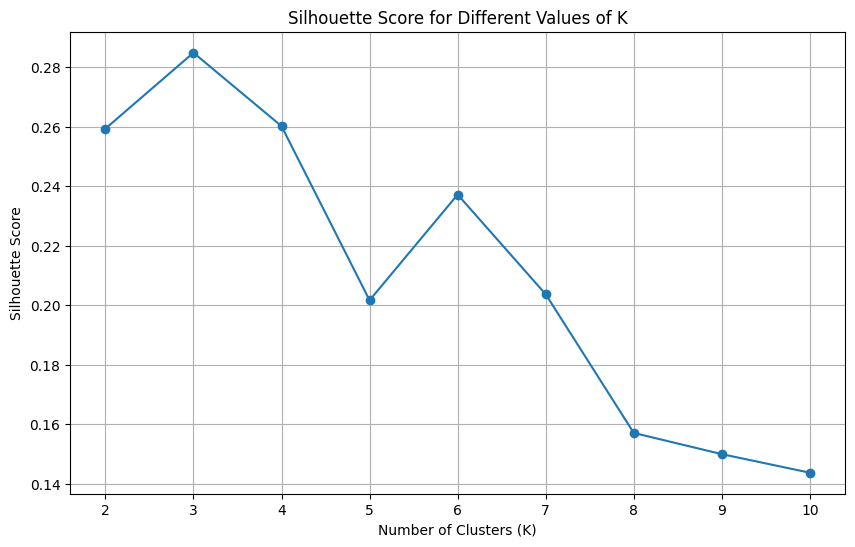

In [59]:
#Compare K Values Using Silhouette Score
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Values of K")

plt.xticks(range(2, 11))
plt.grid()

plt.show()

Cluster   0   1   2
Type               
1         0   0  59
2        65   3   3
3         0  48   0


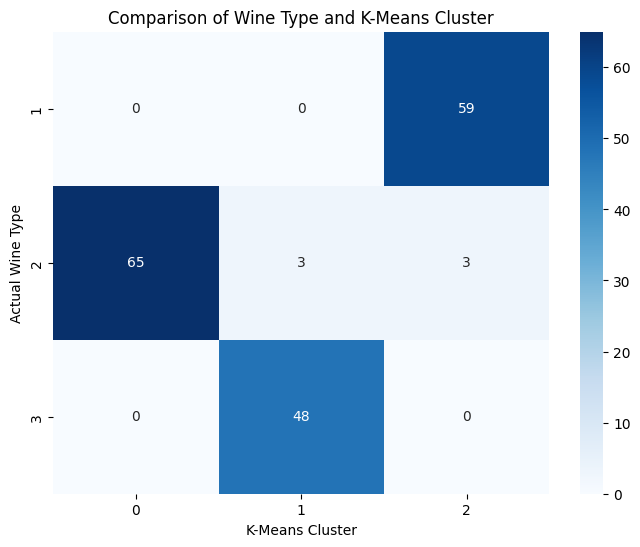

In [61]:
#Compare Original Type with K-Means Cluster
comparison = pd.crosstab(
    df_clustered["Type"],
    df_clustered["Cluster"]
)

print(comparison)
plt.figure(figsize=(8, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Comparison of Wine Type and K-Means Cluster")
plt.xlabel("K-Means Cluster")
plt.ylabel("Actual Wine Type")

plt.show()

# Clustering with PCA Data:

In [62]:
X_pca_final

array([[ 3.31675081e+00,  1.44346263e+00, -1.65739045e-01, ...,
        -6.51390947e-02, -6.41442706e-01,  1.02095585e+00],
       [ 2.20946492e+00, -3.33392887e-01, -2.02645737e+00, ...,
        -1.02441595e+00,  3.08846753e-01,  1.59701372e-01],
       [ 2.51674015e+00,  1.03115130e+00,  9.82818670e-01, ...,
         3.44216131e-01,  1.17783447e+00,  1.13360857e-01],
       ...,
       [-2.67783946e+00,  2.76089913e+00, -9.40941877e-01, ...,
        -4.70238043e-02, -1.22214687e-03, -2.47997312e-01],
       [-2.38701709e+00,  2.29734668e+00, -5.50696197e-01, ...,
        -3.90828774e-01, -5.74476725e-02,  4.91489502e-01],
       [-3.20875816e+00,  2.76891957e+00,  1.01391366e+00, ...,
         2.92913734e-01, -7.41660423e-01, -1.17969019e-01]],
      shape=(178, 10))

In [63]:
print("Original Feature Shape:", X.shape)
print("PCA Feature Shape:", X_pca_final.shape)

Original Feature Shape: (178, 13)
PCA Feature Shape: (178, 10)


In [65]:
#apply k-means to pca data
from sklearn.cluster import KMeans

kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_pca = kmeans_pca.fit_predict(X_pca_final)

#Add PCA Cluster Labels to the Dataset
df_pca_clustered = df.copy()

df_pca_clustered["PCA_Cluster"] = clusters_pca

print(df_pca_clustered.head())

   Type  Alcohol  Malic   Ash  Alcalinity  Magnesium  Phenols  Flavanoids  \
0     1    14.23   1.71  2.43        15.6        127     2.80        3.06   
1     1    13.20   1.78  2.14        11.2        100     2.65        2.76   
2     1    13.16   2.36  2.67        18.6        101     2.80        3.24   
3     1    14.37   1.95  2.50        16.8        113     3.85        3.49   
4     1    13.24   2.59  2.87        21.0        118     2.80        2.69   

   Nonflavanoids  Proanthocyanins  Color   Hue  Dilution  Proline  PCA_Cluster  
0           0.28             2.29   5.64  1.04      3.92     1065            2  
1           0.26             1.28   4.38  1.05      3.40     1050            2  
2           0.30             2.81   5.68  1.03      3.17     1185            2  
3           0.24             2.18   7.80  0.86      3.45     1480            2  
4           0.39             1.82   4.32  1.04      2.93      735            2  


PCA Cluster Distribution:
PCA_Cluster
0    65
1    51
2    62
Name: count, dtype: int64


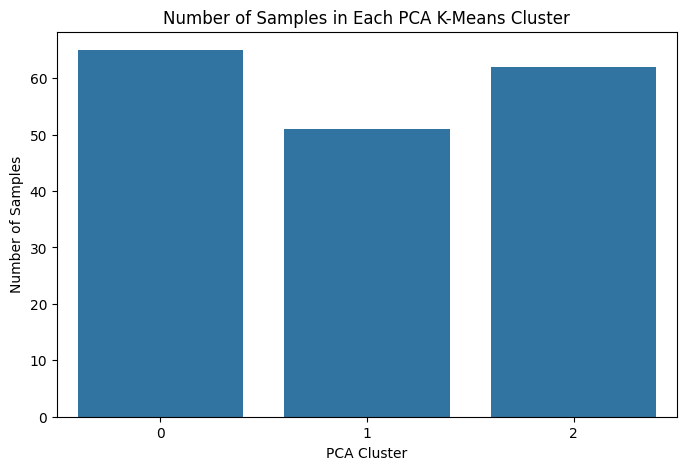

In [67]:
print("PCA Cluster Distribution:")
print(
    df_pca_clustered["PCA_Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_pca_clustered,
    x="PCA_Cluster"
)

plt.title("Number of Samples in Each PCA K-Means Cluster")
plt.xlabel("PCA Cluster")
plt.ylabel("Number of Samples")

plt.show()

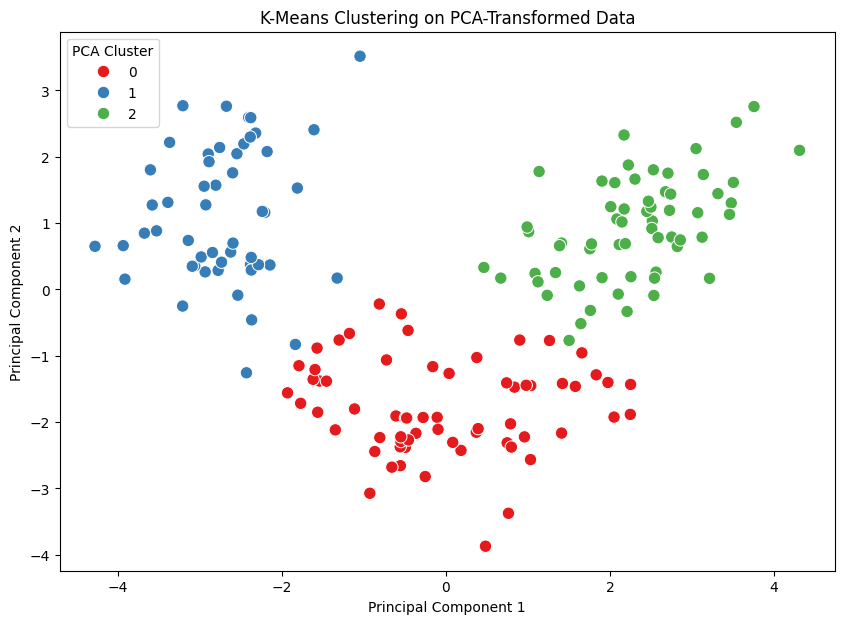

In [68]:
#Visualize PCA Clustering Results
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca_final[:, 0],
    y=X_pca_final[:, 1],
    hue=clusters_pca,
    palette="Set1",
    s=80
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on PCA-Transformed Data")

plt.legend(title="PCA Cluster")

plt.show()

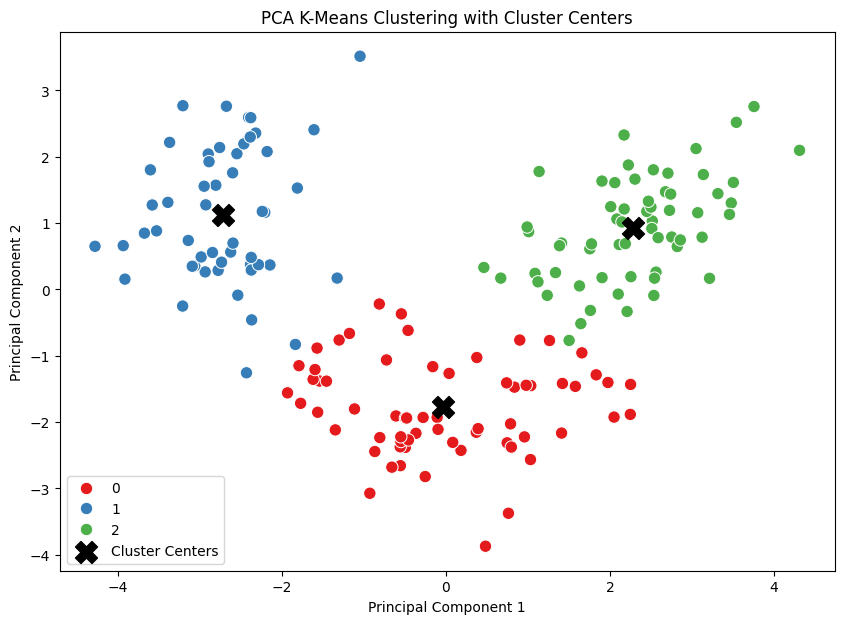

In [69]:
#visualize the pca cluster center
centers_pca_data = kmeans_pca.cluster_centers_

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca_final[:, 0],
    y=X_pca_final[:, 1],
    hue=clusters_pca,
    palette="Set1",
    s=80
)

plt.scatter(
    centers_pca_data[:, 0],
    centers_pca_data[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Cluster Centers"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA K-Means Clustering with Cluster Centers")

plt.legend()

plt.show()

In [70]:
#Compare PCA Clustering with Original Clustering
comparison = pd.DataFrame({
    "Original_Cluster": clusters,
    "PCA_Cluster": clusters_pca
})

comparison.head(20)

,Original_Cluster,PCA_Cluster
0,2,2
1,2,2
2,2,2
3,2,2
4,2,2
5,2,2
6,2,2
7,2,2
8,2,2
9,2,2


PCA_Cluster        0   1   2
Original_Cluster            
0                 65   0   0
1                  0  51   0
2                  0   0  62


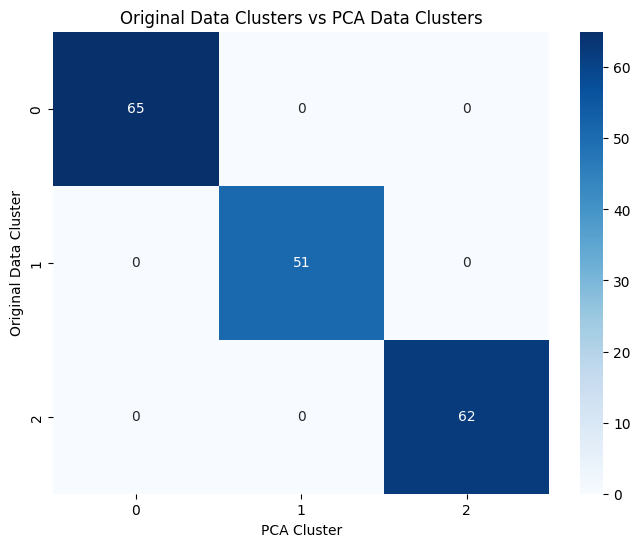

In [72]:
#Cross-Tabulation of the Two Clusterings
cluster_comparison = pd.crosstab(
    comparison["Original_Cluster"],
    comparison["PCA_Cluster"]
)

print(cluster_comparison)

#Visualize the Cluster Comparison
plt.figure(figsize=(8, 6))

sns.heatmap(
    cluster_comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Original Data Clusters vs PCA Data Clusters")
plt.xlabel("PCA Cluster")
plt.ylabel("Original Data Cluster")

plt.show()

In [74]:
#Compare Silhouette Scores
from sklearn.metrics import silhouette_score

silhouette_original = silhouette_score(
    X_scaled,
    clusters
)
silhouette_pca = silhouette_score(
    X_pca_final,
    clusters_pca
)

print("Original Data Silhouette Score:",
      round(silhouette_original, 4))

print("PCA Data Silhouette Score:",
      round(silhouette_pca, 4))

Original Data Silhouette Score: 0.2849
PCA Data Silhouette Score: 0.2987


In [75]:
#Compare Davies–Bouldin Index
from sklearn.metrics import davies_bouldin_score

db_original = davies_bouldin_score(
    X_scaled,
    clusters
)

db_pca = davies_bouldin_score(
    X_pca_final,
    clusters_pca
)

print("Original Data Davies-Bouldin Index:",
      round(db_original, 4))

print("PCA Data Davies-Bouldin Index:",
      round(db_pca, 4))

Original Data Davies-Bouldin Index: 1.3892
PCA Data Davies-Bouldin Index: 1.3363


In [76]:
#Creating a Comparison Table
results = pd.DataFrame({
    "Dataset": [
        "Original Standardized Data",
        "PCA-Transformed Data"
    ],
    
    "Number of Features": [
        X_scaled.shape[1],
        X_pca_final.shape[1]
    ],
    
    "Number of Clusters": [
        3,
        3
    ],
    
    "Silhouette Score": [
        silhouette_original,
        silhouette_pca
    ],
    
    "Davies-Bouldin Index": [
        db_original,
        db_pca
    ]
})

print(results.round(4))

                      Dataset  Number of Features  Number of Clusters  \
0  Original Standardized Data                  13                   3   
1        PCA-Transformed Data                  10                   3   

   Silhouette Score  Davies-Bouldin Index  
0            0.2849                1.3892  
1            0.2987                1.3363  


col_0   0   1   2
Type             
1       0   0  59
2      65   3   3
3       0  48   0


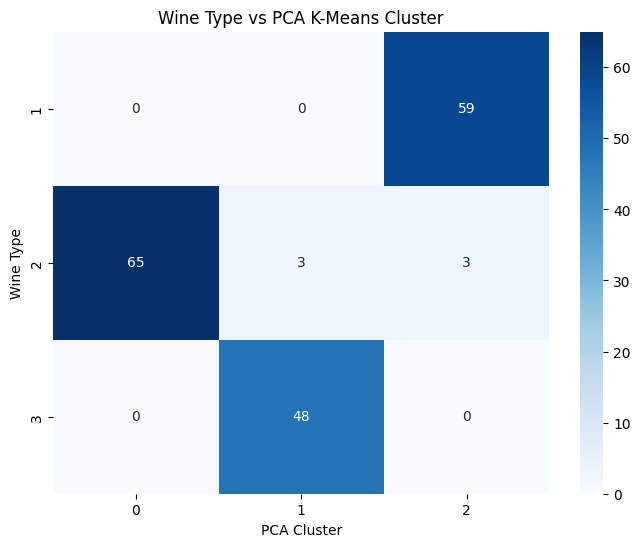

In [77]:
#Comparing Actual Wine Types with PCA Clusters
type_pca_comparison = pd.crosstab(
    df["Type"],
    clusters_pca
)

print(type_pca_comparison)


plt.figure(figsize=(8, 6))

sns.heatmap(
    type_pca_comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Wine Type vs PCA K-Means Cluster")
plt.xlabel("PCA Cluster")
plt.ylabel("Wine Type")

plt.show()

# Comparison and Analysis:

In [78]:
#Creating a Comparison Table
comparison_results = pd.DataFrame({
    "Dataset": [
        "Original Standardized Data",
        "PCA-Transformed Data"
    ],
    
    "Number of Features": [
        X_scaled.shape[1],
        X_pca_final.shape[1]
    ],
    
    "Number of Clusters": [
        3,
        3
    ],
    
    "Silhouette Score": [
        silhouette_original,
        silhouette_pca
    ],
    
    "Davies-Bouldin Index": [
        db_original,
        db_pca
    ]
})

print(comparison_results.round(4))

                      Dataset  Number of Features  Number of Clusters  \
0  Original Standardized Data                  13                   3   
1        PCA-Transformed Data                  10                   3   

   Silhouette Score  Davies-Bouldin Index  
0            0.2849                1.3892  
1            0.2987                1.3363  


In [80]:
#Compare Silhouette Scores
print("Original Data Silhouette Score:",
      round(silhouette_original, 4))

print("PCA Data Silhouette Score:",
      round(silhouette_pca, 4))

difference_silhouette = silhouette_pca - silhouette_original

print("Difference:",
      round(difference_silhouette, 4))

if silhouette_pca > silhouette_original:
    print("PCA clustering has a higher Silhouette Score.")
elif silhouette_pca < silhouette_original:
    print("Original-data clustering has a higher Silhouette Score.")
else:
    print("Both approaches have the same Silhouette Score.")

Original Data Silhouette Score: 0.2849
PCA Data Silhouette Score: 0.2987
Difference: 0.0138
PCA clustering has a higher Silhouette Score.


In [81]:
#Compare Davies–Bouldin Index
print("Original Data Davies-Bouldin Index:",
      round(db_original, 4))

print("PCA Data Davies-Bouldin Index:",
      round(db_pca, 4))

difference_db = db_pca - db_original

print("Difference:",
      round(difference_db, 4))


if db_pca < db_original:
    print("PCA clustering has a lower Davies-Bouldin Index.")
elif db_pca > db_original:
    print("Original-data clustering has a lower Davies-Bouldin Index.")
else:
    print("Both approaches have the same Davies-Bouldin Index.")

Original Data Davies-Bouldin Index: 1.3892
PCA Data Davies-Bouldin Index: 1.3363
Difference: -0.0529
PCA clustering has a lower Davies-Bouldin Index.


In [83]:
#Compare Cluster Assignments
cluster_comparison = pd.DataFrame({
    "Original_Cluster": clusters,
    "PCA_Cluster": clusters_pca
})

cluster_comparison.head(20)

,Original_Cluster,PCA_Cluster
0,2,2
1,2,2
2,2,2
3,2,2
4,2,2
5,2,2
6,2,2
7,2,2
8,2,2
9,2,2


In [84]:
#Creating a cross-tabulation
cluster_cross_tab = pd.crosstab(
    cluster_comparison["Original_Cluster"],
    cluster_comparison["PCA_Cluster"]
)

print(cluster_cross_tab)

PCA_Cluster        0   1   2
Original_Cluster            
0                 65   0   0
1                  0  51   0
2                  0   0  62


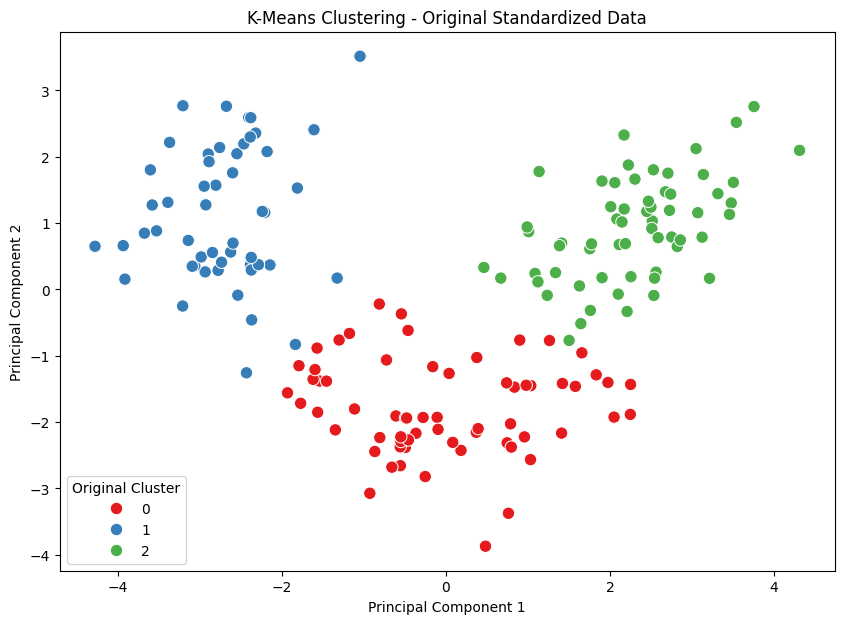

In [85]:
#Visualize Both Clustering Results
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters,
    palette="Set1",
    s=80
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering - Original Standardized Data")

plt.legend(title="Original Cluster")

plt.show()

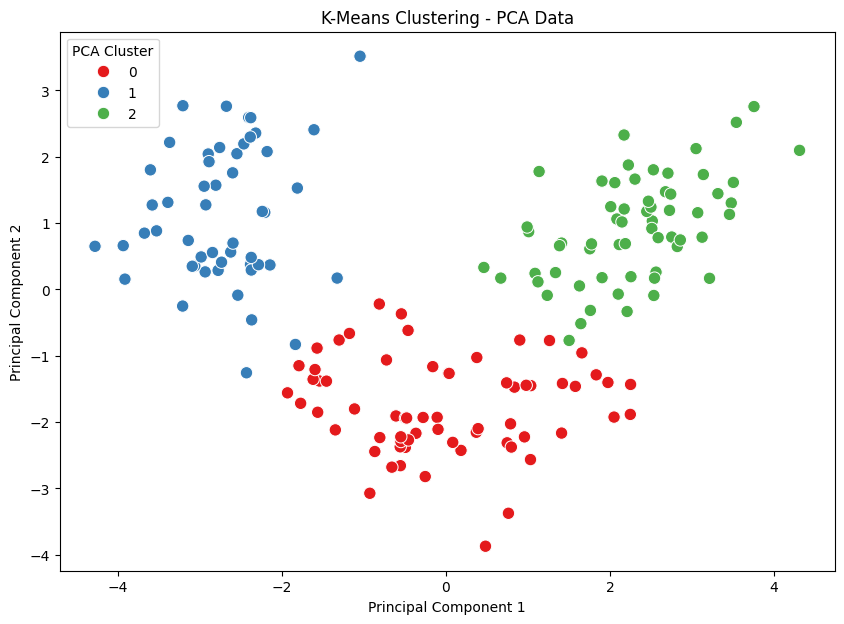

In [86]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca_final[:, 0],
    y=X_pca_final[:, 1],
    hue=clusters_pca,
    palette="Set1",
    s=80
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering - PCA Data")

plt.legend(title="PCA Cluster")

plt.show()

   Original Data  PCA Data
0             65        65
1             51        51
2             62        62


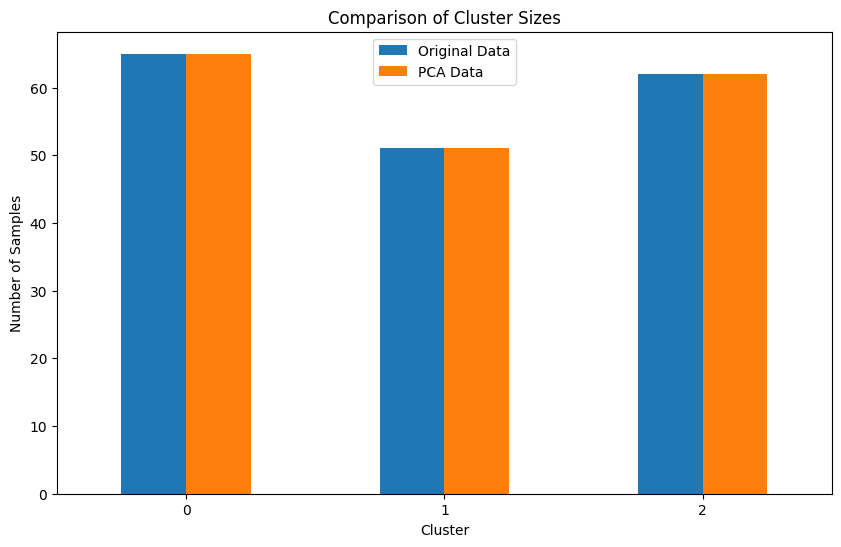

In [88]:
#Compare Cluster Sizes
original_sizes = pd.Series(clusters).value_counts().sort_index()
pca_sizes = pd.Series(clusters_pca).value_counts().sort_index()

cluster_sizes = pd.DataFrame({
    "Original Data": original_sizes,
    "PCA Data": pca_sizes
})

print(cluster_sizes)

#visualizing
cluster_sizes.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.title("Comparison of Cluster Sizes")

plt.xticks(rotation=0)
plt.show()

In [89]:
#Quantify the Dimensionality Reduction
original_features = X_scaled.shape[1]
pca_features = X_pca_final.shape[1]

reduction_percentage = (
    (original_features - pca_features)
    / original_features
) * 100

print("Original Features:", original_features)
print("PCA Features:", pca_features)
print(
    "Dimensionality Reduction:",
    round(reduction_percentage, 2),
    "%"
)

Original Features: 13
PCA Features: 10
Dimensionality Reduction: 23.08 %


# Conclusion and Insights

#### 1.Summarize the key findings and insights from the assignment.

Dataset and EDA findings

    The Wine dataset contains 178 records, 13 numerical features, and one target/class column, Type.
    The dataset contains no missing values and no duplicate records, so no major data-cleaning operation was required.
    The Type column represents three wine classes and was not used as an input feature for PCA or K-Means, because both techniques were applied as unsupervised analysis methods.
    The EDA showed that the numerical features have different scales, making standardization important before PCA and K-Means.
    Several features showed strong correlations. For example, Phenols and Flavanoids have a strong positive relationship. This indicates that some features contain overlapping information.

PCA findings
    
    The 13 numerical features were standardized using StandardScaler.
    PCA transformed the original correlated features into a smaller set of uncorrelated principal components.
    The scree plot and cumulative explained variance were used to determine the number of components.
    10 principal components were selected to preserve approximately 95%+ of the total variance in the dataset.
    PCA reduced the feature space from 13 dimensions to 10 dimensions while retaining most of the information.
K-Means clustering findings

    K-Means clustering was performed with K = 3, corresponding to the three classes present in the dataset.
    Clustering was performed in two ways:
    On the original standardized 13-feature dataset.
    On the PCA-transformed 10-feature dataset.
    The Elbow Method was used to study the appropriate number of clusters.
    Silhouette Score and Davies-Bouldin Index were used to evaluate clustering quality.

 #### 2.Discuss the practical implications of using PCA and clustering in data analysis.

PCA in practical data analysis

    PCA is particularly useful when a dataset contains many numerical features and some of them are highly correlated

    Reduce the number of variables.
    Remove redundancy caused by correlated features.
    Reduce computational complexity.
    Make high-dimensional data easier to visualize.
    Improve the efficiency of some machine-learning algorithms.
    Transform correlated variables into orthogonal principal components.

    example: instead of working with all 13 Wine features, the analysis can work with a smaller number of principal components while preserving most of the dataset's variation.

    limitation: principal components are combinations of the original variables, so they can be harder to interpret than the original features.

K-Means clustering in practical data analysis

    K-Means is useful when we want to discover groups in data without using predefined class labels.

    K-Means can help identify groups of wines with similar characteristics based on their chemical measurements.

Practical applications include:

    Customer segmentation.
    Product grouping.
    Market segmentation.
    Document clustering.
    Image compression.
    Biological data analysis.
    Identifying groups with similar characteristics.

    K-Means works particularly well when the variables have been appropriately scaled and the groups are reasonably well represented by cluster centers.

#### 3.Provide recommendations for when to use each technique based on the analysis conducted.

When to use PCA
    
    There are many numerical features.
    Features are strongly correlated.
    Dimensionality needs to be reduced.
    Computational efficiency is important.
    You want to visualize high-dimensional data in 2D or 3D.
    Most of the important information can be represented using fewer components.

When not to rely only on PCA

    Interpretability of the original variables is very important.
    Every feature has specific business or scientific meaning.
    Low-variance features may contain important information for the particular task.
    The objective is classification or clustering separation rather than variance preservation alone.

When to use K-Means

    You want to discover natural groups in unlabeled data.
    The dataset contains numerical features.
    The data can reasonably be represented by cluster centers.
    You have a reasonable estimate or method for selecting K.
    You want a relatively simple and computationally efficient clustering algorithm.

When to Combine PCA and KMeans

    PCA and K-Means can be used together when a dataset has many correlated numerical features.